# 02 · 再聴曲線と下限Lの候補

主タスクT2の**学習ペアだけ**で候補を記録し、その後に検証・テストを記述的に確認します。Lは自動変更しません。候補選定は90日を追跡できる全活動層で行い、EDA時点のLに依存する活動選択を避けます。主分析の30日以上活動の曲線も別に出します。

In [1]:
from pathlib import Path
import numpy as np
import polars as pl
from IPython.display import display, Image
from relisten import config
np.random.seed(config.SEED)
print("作業フォルダ:", config.ROOT)

作業フォルダ: /Users/macuser/dev/paper1


## 学習期間だけで選ぶ

日ごとの初回自発再聴率は、最初の再聴が `(d-1,d]` 日にあるペア数を起点コホート全体で割った値です。30〜90日目の平均の2倍以内になる最初の日を求め、指定候補に丸めます。T1/B/O2の比較も学習期間だけで先に描きます。

In [2]:
from relisten.eda import training_eda, descriptive_eda
candidate = training_eda()
display(candidate)

{'task': 'T2',
 'split': 'train',
 'cohort': 'all complete-followup anchors; no activity selection',
 'pairs': 848521,
 'tail_daily_mean': 0.0005908448492083071,
 'threshold': 0.0011816896984166141,
 'crossing_day': 10,
 'candidate_lower_days': 7,
 'configured_lower_days': 1,
 'approved': False,
 'rounding': 'nearest among 1,3,7,14; smaller value on ties'}

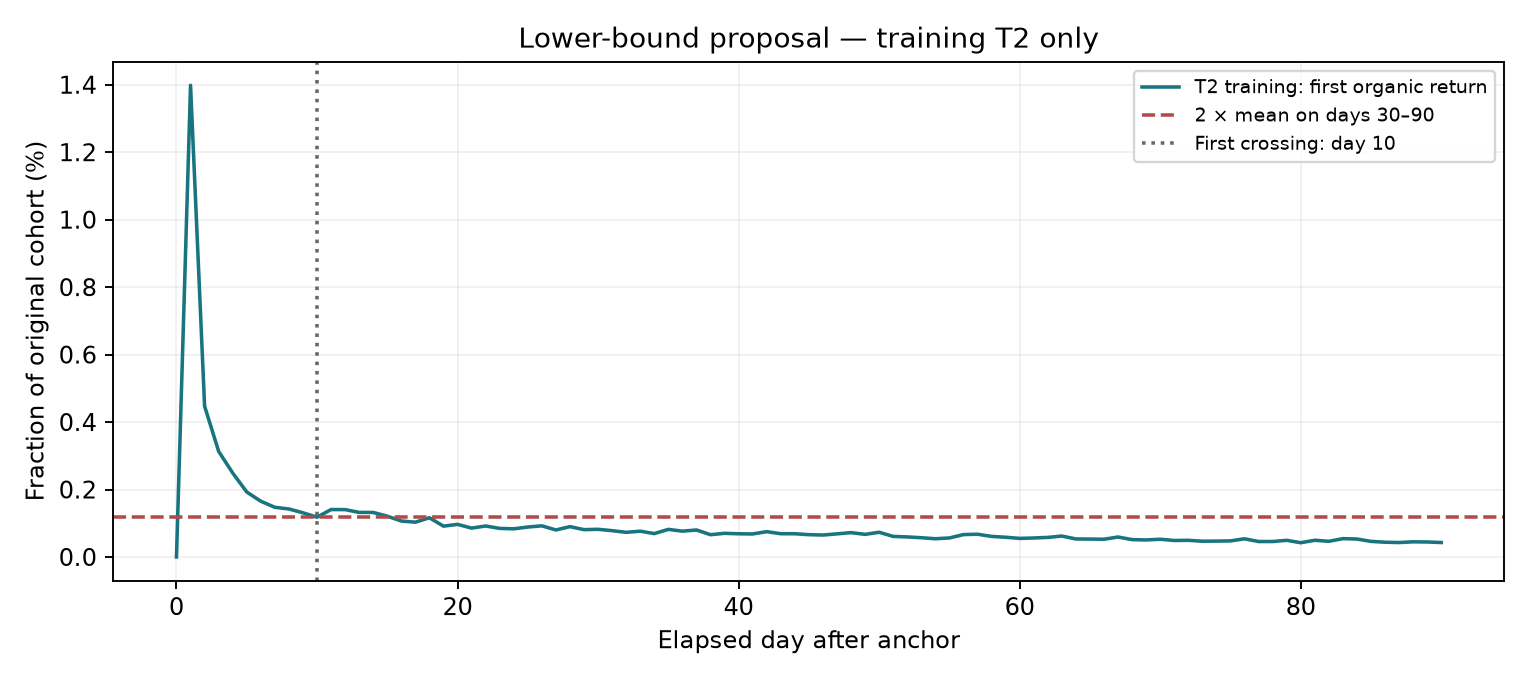

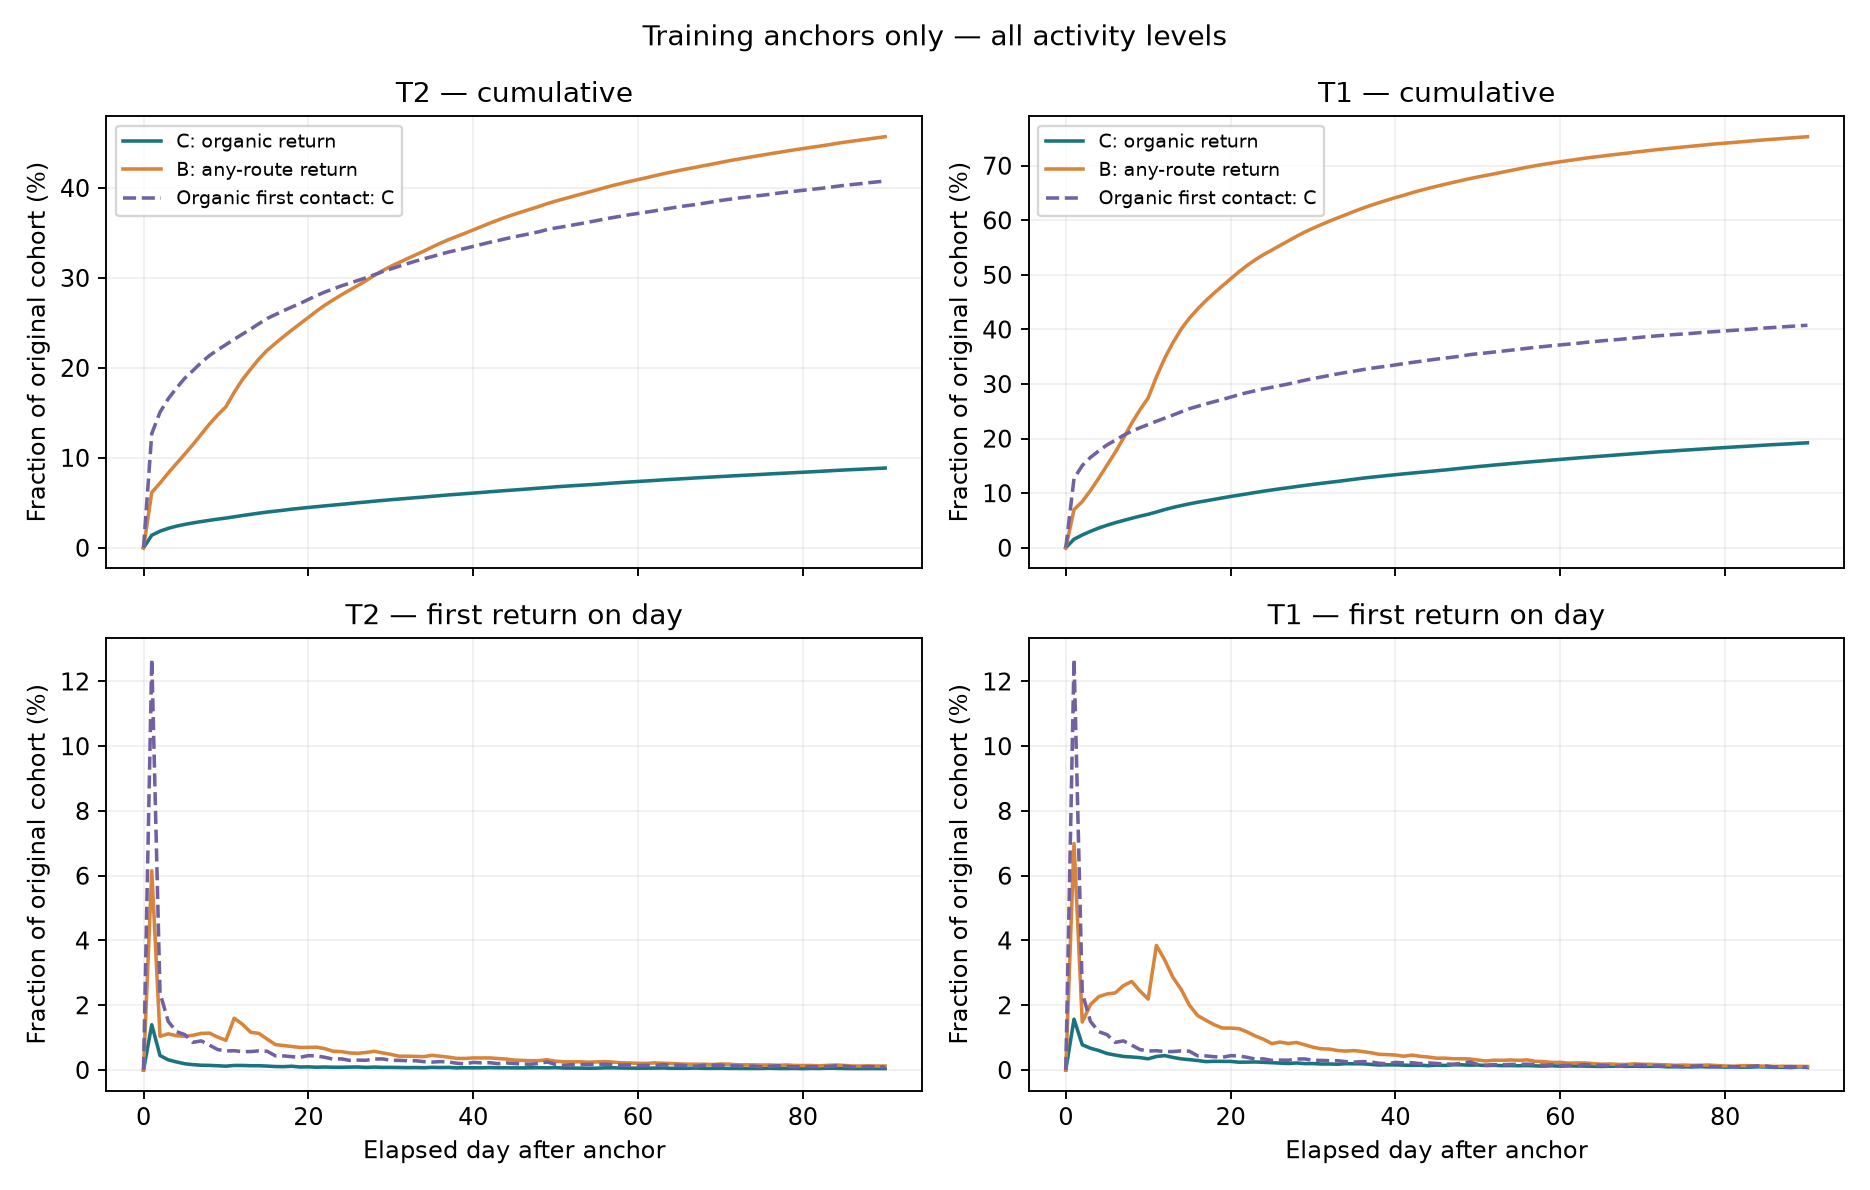

In [3]:
display(Image(filename=str(config.RESULTS / "figures/lower_bound_selection.png")))
display(Image(filename=str(config.RESULTS / "figures/train_return_curves.png")))

## 候補の保存後に、各分割と活動条件を確認

以下の結果は候補を変更するためには使いません。活動量別と人気度別の曲線、24時間以内の再聴、再生率、ユーザー活動日数、149日までに出現しない曲と埋め込みの収録率を保存します。人気度は全起点より前の0〜29日で測り、未来の人気度を使いません。

In [4]:
candidate, comparison = descriptive_eda()
display(comparison.sort("lower_days", "split"))

task,split,pairs,users,positive_rate_c,positive_rate_b,lower_days,horizon_days,min_active_days
str,str,i64,i64,f64,f64,i64,i64,i64
"""T2""","""test""",967884,4819,0.096279,0.431502,1,90,30
"""T2""","""train""",755797,3554,0.090176,0.45425,1,90,30
"""T2""","""validation""",283134,3856,0.105275,0.459479,1,90,30
"""T2""","""test""",958060,4775,0.094023,0.424451,3,90,30
"""T2""","""train""",750812,3526,0.08781,0.446453,3,90,30
…,…,…,…,…,…,…,…,…
"""T2""","""train""",739927,3463,0.08491,0.432682,7,90,30
"""T2""","""validation""",275285,3746,0.100143,0.439683,7,90,30
"""T2""","""test""",905038,4518,0.084515,0.374261,14,90,30


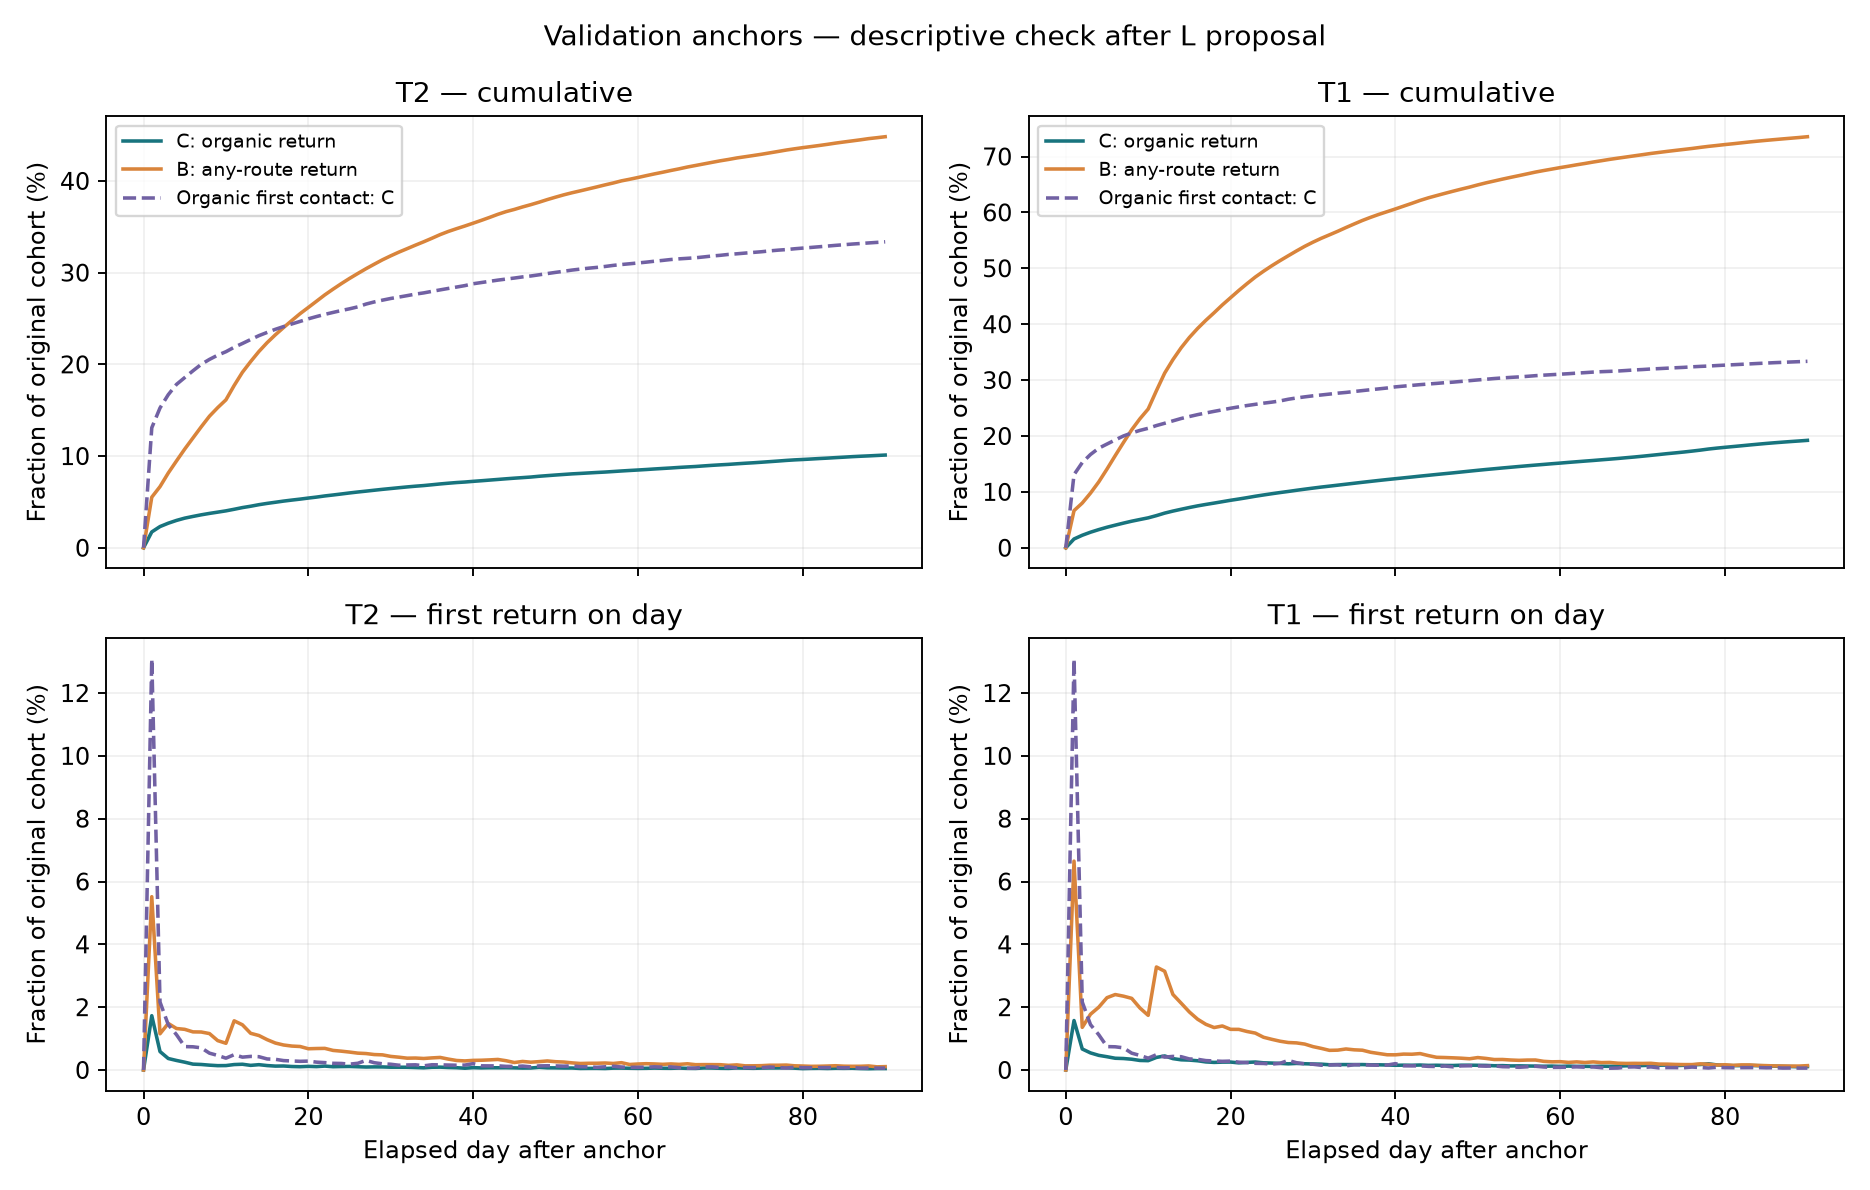

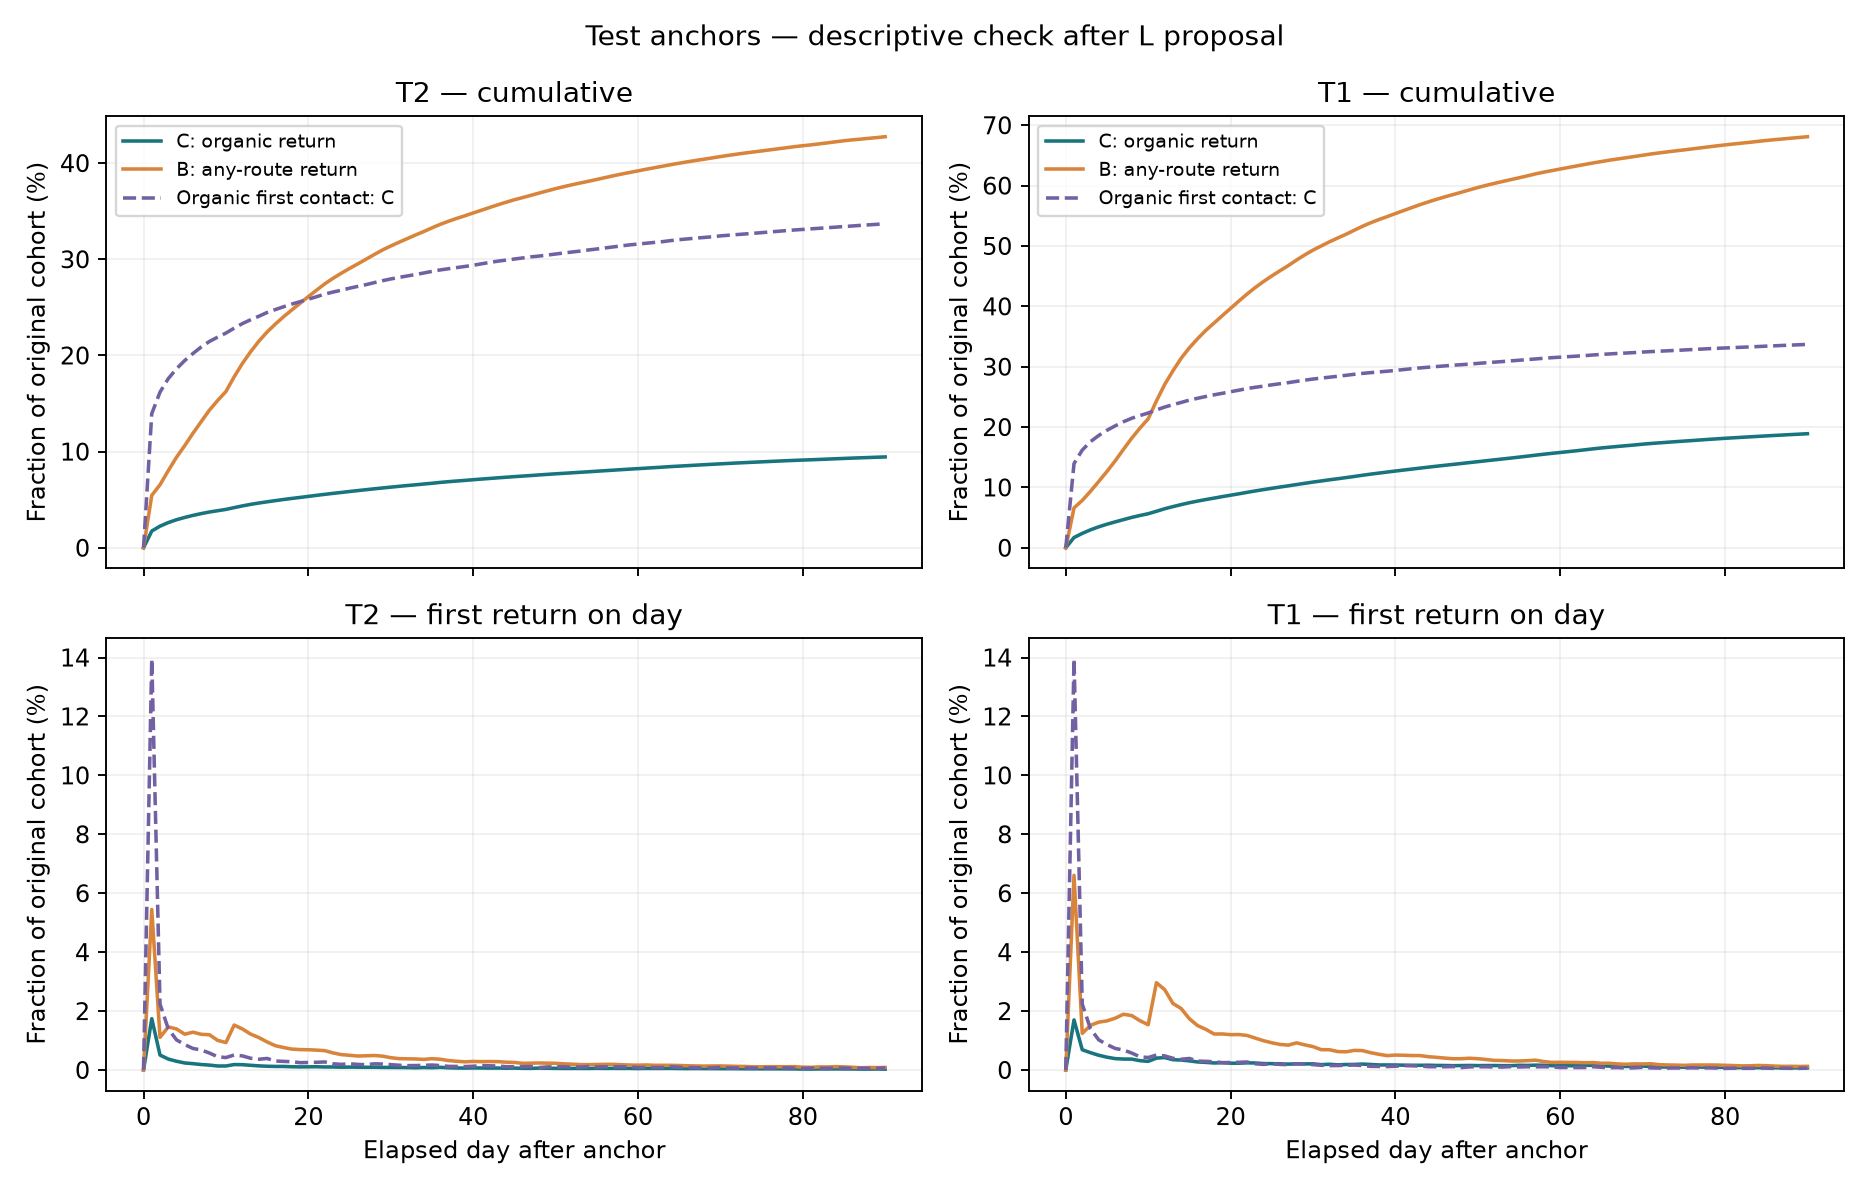

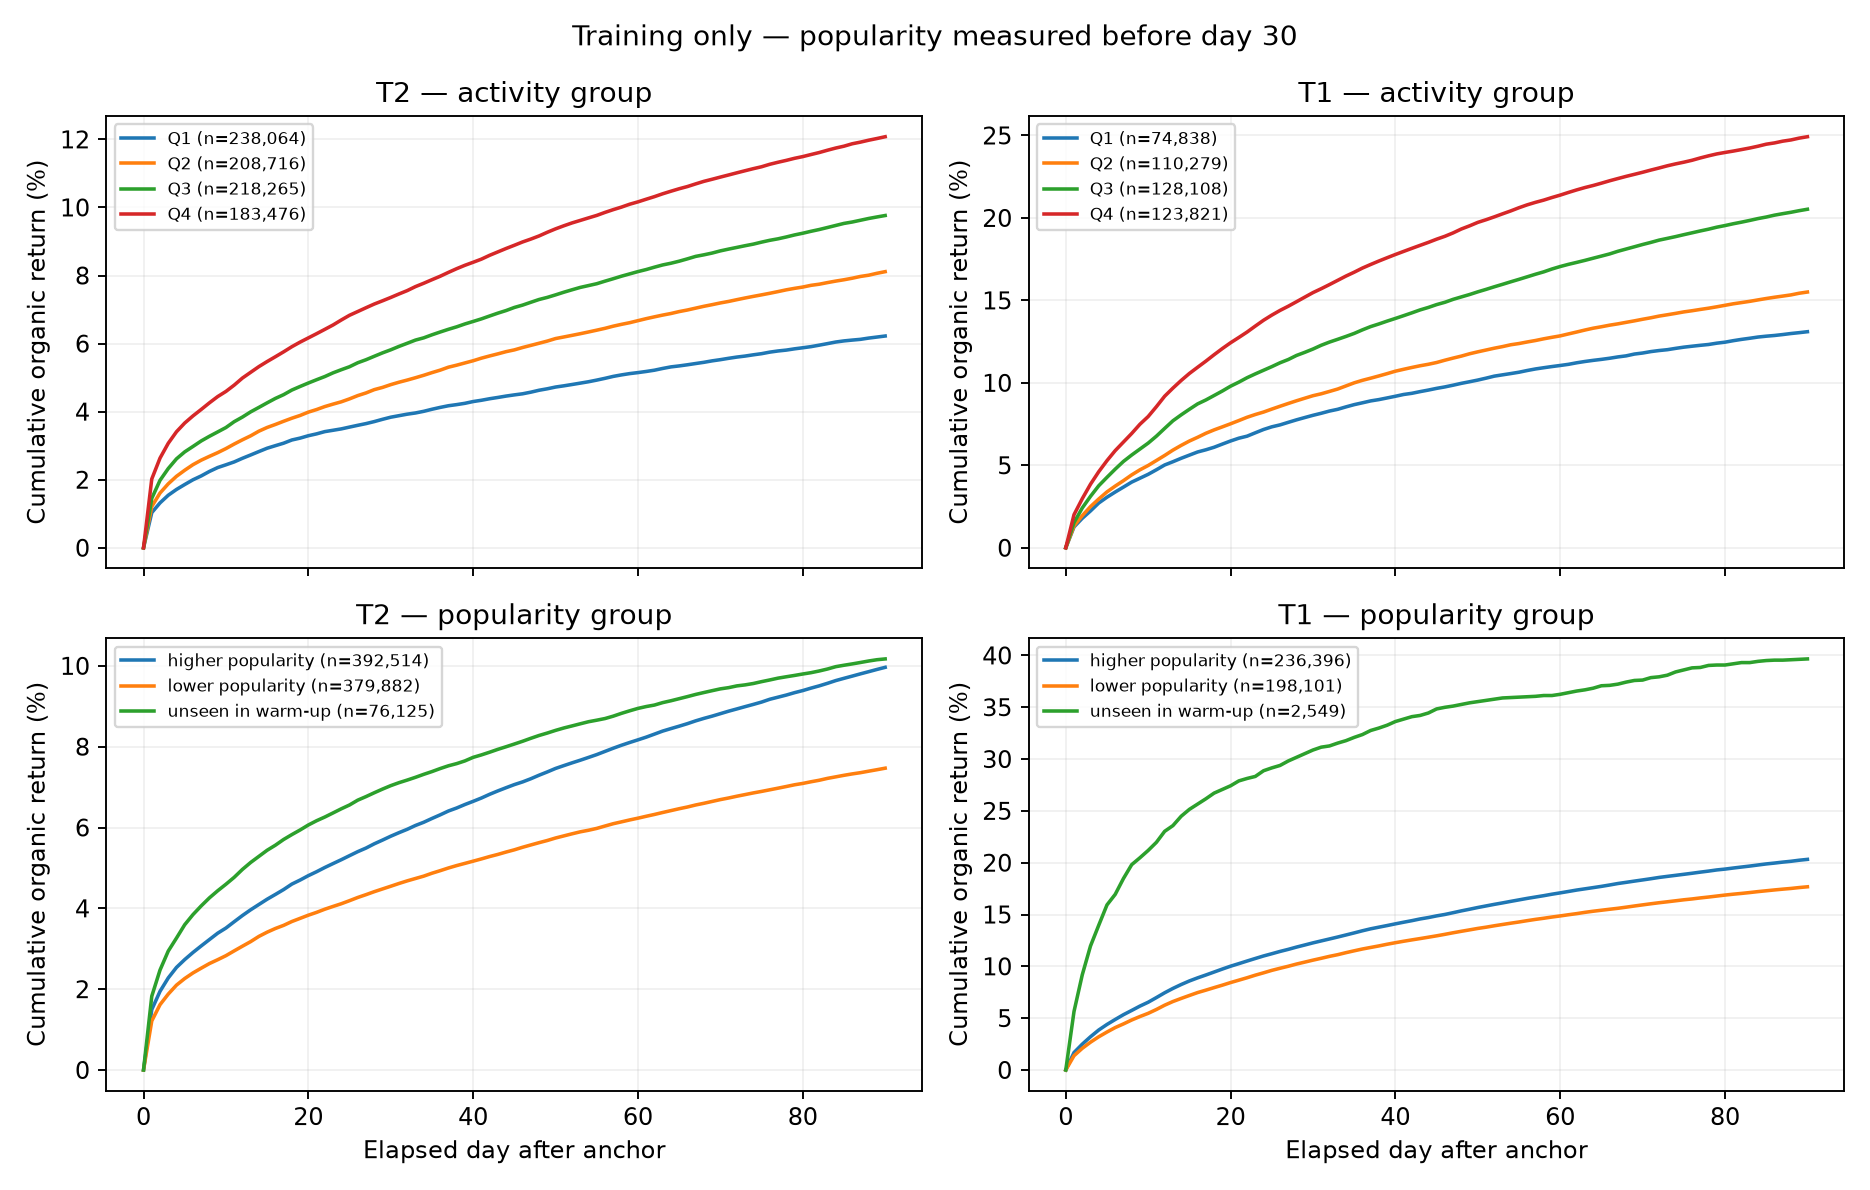

In [5]:
display(Image(filename=str(config.RESULTS / "figures/validation_return_curves.png")))
display(Image(filename=str(config.RESULTS / "figures/test_return_curves.png")))
display(Image(filename=str(config.RESULTS / "figures/train_stratified_curves.png")))

In [6]:
for name in ["returns_within_24h.csv", "played_ratio_quantiles.csv", "t2_cold_items.csv", "embedding_coverage.csv"]:
    print(name)
    display(pl.read_csv(config.RESULTS / name))

returns_within_24h.csv


split,task,route,pairs,within_24h,rate
str,str,str,i64,i64,f64
"""train""","""T2""","""B""",848521,52215,0.061536
"""train""","""T2""","""C""",848521,11864,0.013982
"""train""","""T1""","""B""",437046,30561,0.069926
"""train""","""T1""","""C""",437046,6857,0.015689
"""train""","""O2""","""B""",446511,57453,0.128671
…,…,…,…,…,…
"""test""","""T2""","""C""",1099784,19152,0.017414
"""test""","""T1""","""B""",1064245,70299,0.066055
"""test""","""T1""","""C""",1064245,18086,0.016994


played_ratio_quantiles.csv


q0,q0.1,q0.25,q0.5,q0.75,q0.9,q0.99,q1
f64,f64,f64,f64,f64,f64,f64,f64
0.0,1.0,7.0,100.0,100.0,100.0,100.0,159.0


t2_cold_items.csv


split,unique_items,cold_item_fraction,embedded_item_fraction
str,i64,f64,f64
"""validation""",82967,0.117312,0.966505
"""train""",125868,0.0,0.962087
"""test""",160366,0.217789,0.966433


embedding_coverage.csv


items,embedded_items,fraction,revision
i64,i64,f64,str
877168,819432,0.934179,"""dd6f3a19eef5866e346c3270e098ba…"


## 主ラベル決定済み

TMはモデル結果を見る前に、概念上の理由でL=1を採用しました。正解窓は推薦再生から24時間以降・90日後まで（両端を含む）です。EDA規則の候補7は履歴として保持し、L=7・14を感度分析のモデル結果表に必ず含めてマイルストーン3以降へ進みます。